In [9]:
# 1. LIBRARIES & SETUP

import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import scipy.stats as stats
import yfinance as yf

In [13]:
print("Loading and filtering HANZE database...")

df_events = pd.read_csv('/Users/nico/Desktop/Climate change event study/Climate change event study/HANZE_events.csv')

display(df_events.head())

Loading and filtering HANZE database...


,ID,Country code,Year,Country name,Start date,End date,Type,Flood source,Regions affected (v2010),Regions affected (v2021),Area flooded,Fatalities,Persons affected,Losses (nominal value),Losses (original currency),Losses (2020 euro),Cause,Notes,References,Changes
0,2000,AL,1946,Albania,1946-10-11,1946-11-15,River,NaN,AL011;AL012;AL013;AL015;AL021;AL022;AL031;AL03...,AL011;AL012;AL013;AL015;AL021;AL022;AL031;AL03...,NaN,15.0,NaN,1.000000e+09,ALK,29746037.0,Heavy rainfall,Also landslides,UNDRR (2022),New
1,2001,AL,1953,Albania,1953-12-12,1953-12-12,Flash,NaN,AL014;AL015,AL014;AL015,NaN,5.0,NaN,8.000000e+07,ALK,2379683.0,Extreme rainfall,NaN,UNDRR (2022),New
2,2002,AL,1960,Albania,1960-11-07,1960-11-07,Flash,NaN,AL022;AL032;AL035,AL022;AL032;AL035,NaN,4.0,NaN,NaN,NaN,NaN,Extreme rainfall,NaN,UNDRR (2022),New
3,2003,AL,1962,Albania,1962-11-15,1962-11-16,River,Drin; Buna; Semani; Vjosa,AL011;AL012;AL013;AL014;AL015;AL021;AL022;AL03...,AL011;AL012;AL013;AL014;AL015;AL021;AL022;AL03...,995.0,9.0,NaN,2.000000e+09,ALK,59492073.0,Heavy rainfall,Flood impact continued into 1963; Impact area ...,UNDRR (2022); GIZ (2018); Bogdani and Selenica...,New
4,2532,AL,1968,Albania,1968-12-17,1968-12-17,Flash,NaN,AL015,AL015,15.0,0.0,NaN,NaN,NaN,NaN,Extreme rainfall,NaN,UNDRR (2022),New


In [11]:
# 2. HANZE DATABASE: FILTERING TOP 3 FLOODS (2000 - 2020)

# Format dates and numeric values
df_events['Start date'] = pd.to_datetime(df_events['Start date'], errors='coerce')
df_events['Year'] = pd.to_numeric(df_events['Year'], errors='coerce')
df_events['Losses (2020 euro)'] = pd.to_numeric(df_events['Losses (2020 euro)'], errors='coerce')

# Filter period: 2000 to 2020
df_period = df_events[(df_events['Year'] >= 2000) & (df_events['Year'] <= 2020)]

# Extract the Top 3 largest floods based on economic losses
top_3_floods = df_period.nlargest(3, 'Losses (2020 euro)')

print("\n--- Top 3 Largest Flood Events (2000-2020) ---")
for i, row in top_3_floods.iterrows():
    print(f"{row['Country name']} ({row['Year']}) | Date: {row['Start date'].strftime('%Y-%m-%d')} | Losses: €{row['Losses (2020 euro)']:,}")


--- Top 3 Largest Flood Events (2000-2020) ---
Germany (2002) | Date: 2002-08-11 | Losses: €12,939,505,957.0
Germany (2013) | Date: 2013-05-28 | Losses: €9,201,215,293.0
United Kingdom (2007) | Date: 2007-06-15 | Losses: €4,684,313,535.0


In [16]:
# 3. FINANCIAL DATA DOWNLOAD (YAHOO FINANCE)

import yfinance as yf
import pandas as pd
import numpy as np

tickers = ['ALV.DE', 'MUV2.DE', 'SREN.SW']
benchmark = ['^STOXX']

print("\nDownloading financial data...")

# Initialize an empty DataFrame to build columns directly
clean_prices = pd.DataFrame()

for ticker in (tickers + benchmark):
    # Download each ticker individually
    df_temp = yf.download(ticker, start='1998-01-01', end='2021-12-31')
    
    if df_temp.empty:
        print(f"Warning: No data fetched for {ticker}")
        continue
        
    # Flatten MultiIndex columns if Yahoo Finance nested them
    if isinstance(df_temp.columns, pd.MultiIndex):
        df_temp.columns = df_temp.columns.get_level_values(0)
    
    # Standardize column names to Title Case to prevent case-sensitivity misses
    df_temp.columns = df_temp.columns.str.title()
    
    # Extract the preferred pricing column directly into the DataFrame
    if 'Adj Close' in df_temp.columns:
        clean_prices[ticker] = df_temp['Adj Close']
    elif 'Close' in df_temp.columns:
        clean_prices[ticker] = df_temp['Close']
    else:
        # Fallback to the very first column if headers are entirely unrecognizable
        clean_prices[ticker] = df_temp.iloc[:, 0]

# Separate the stocks from the market benchmark
stock_prices = clean_prices[tickers].dropna()
market_prices = clean_prices[benchmark].dropna()

# Calculate daily logarithmic returns
stock_returns = np.log(stock_prices / stock_prices.shift(1)).dropna()
market_returns = np.log(market_prices / market_prices.shift(1)).dropna()

# Align the temporal indices exactly
common_index = stock_returns.index.intersection(market_returns.index)
stock_returns = stock_returns.loc[common_index]
market_returns = market_returns.loc[common_index]

print("Data successfully downloaded and aligned!")

[*********************100%***********************]  1 of 1 completed


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed

Data successfully downloaded and aligned!


In [17]:
# 3.5. DATA INTEGRITY CHECK (HEADS & SHAPES)

print("--- Data Integrity Check ---")
print(f"Total aligned trading days: {len(stock_returns)}")

print("\nFirst 5 rows of Log Returns (Insurance Stocks):")
display(stock_returns.head())

print("\nFirst 5 rows of Log Returns (Market Benchmark - STOXX 600):")
display(market_returns.head())

--- Data Integrity Check ---
Total aligned trading days: 4435

First 5 rows of Log Returns (Insurance Stocks):


,ALV.DE,MUV2.DE,SREN.SW
Date,,,
2004-04-27,-0.002062,-0.002991,0.029422
2004-04-28,-0.018088,-0.014545,-0.025916
2004-04-29,-0.012803,-0.016855,-0.007026
2004-04-30,-0.008326,-0.004314,0.002348
2004-05-03,-0.002942,-0.006562,0.007591



First 5 rows of Log Returns (Market Benchmark - STOXX 600):


,^STOXX
Date,
2004-04-27,-0.000607
2004-04-28,-0.014440
2004-04-29,-0.008790
2004-04-30,-0.009161
2004-05-03,0.005590


In [18]:
assert stock_returns.isna().sum().sum() == 0, "Missing values found in stock returns!"
assert market_returns.isna().sum().sum() == 0, "Missing values found in market returns!"
print("\nSuccess: No missing values detected in the aligned returns.")


Success: No missing values detected in the aligned returns.


In [24]:
# 4. EVENT STUDY FUNCTIONS (CAPM & CAR)

def get_nearest_trading_day(target_date, trading_index):
    """Finds the closest trading day if the event happened on a weekend/holiday."""
    if target_date.tzinfo is not None and trading_index.tz is None:
         target_date = target_date.replace(tzinfo=None)
            
    nearest_idx = trading_index.get_indexer([target_date], method='nearest')[0]
    return trading_index[nearest_idx]

def estimate_capm(stock_ret, market_ret, event_date):
    """Estimates CAPM parameters using the [-250, -20] estimation window."""
    event_idx = stock_ret.index.get_loc(event_date)
    est_start, est_end = event_idx - 250, event_idx - 20
    
    # Prevent negative indexing which wraps to the end of the array
    if est_start < 0:
        raise IndexError("Not enough historical data for estimation window.")
        
    y = stock_ret.iloc[est_start:est_end]
    x = market_ret.iloc[est_start:est_end]
    x = sm.add_constant(x)
    
    return sm.OLS(y, x).fit()

def calculate_car(model, stock_ret, market_ret, event_date):
    """Calculates Abnormal Returns and CAR using the [-20, +20] event window."""
    event_idx = stock_ret.index.get_loc(event_date)
    window_start, window_end = event_idx - 20, event_idx + 21
    
    # Prevent negative indexing to fix the shape (0,) crash
    if window_start < 0:
        raise IndexError("Not enough historical data for event window.")
        
    actual_returns = stock_ret.iloc[window_start:window_end]
    market_window = sm.add_constant(market_ret.iloc[window_start:window_end])
    
    expected_returns = model.predict(market_window)
    abnormal_returns = actual_returns - expected_returns
    
    return abnormal_returns, abnormal_returns.cumsum()

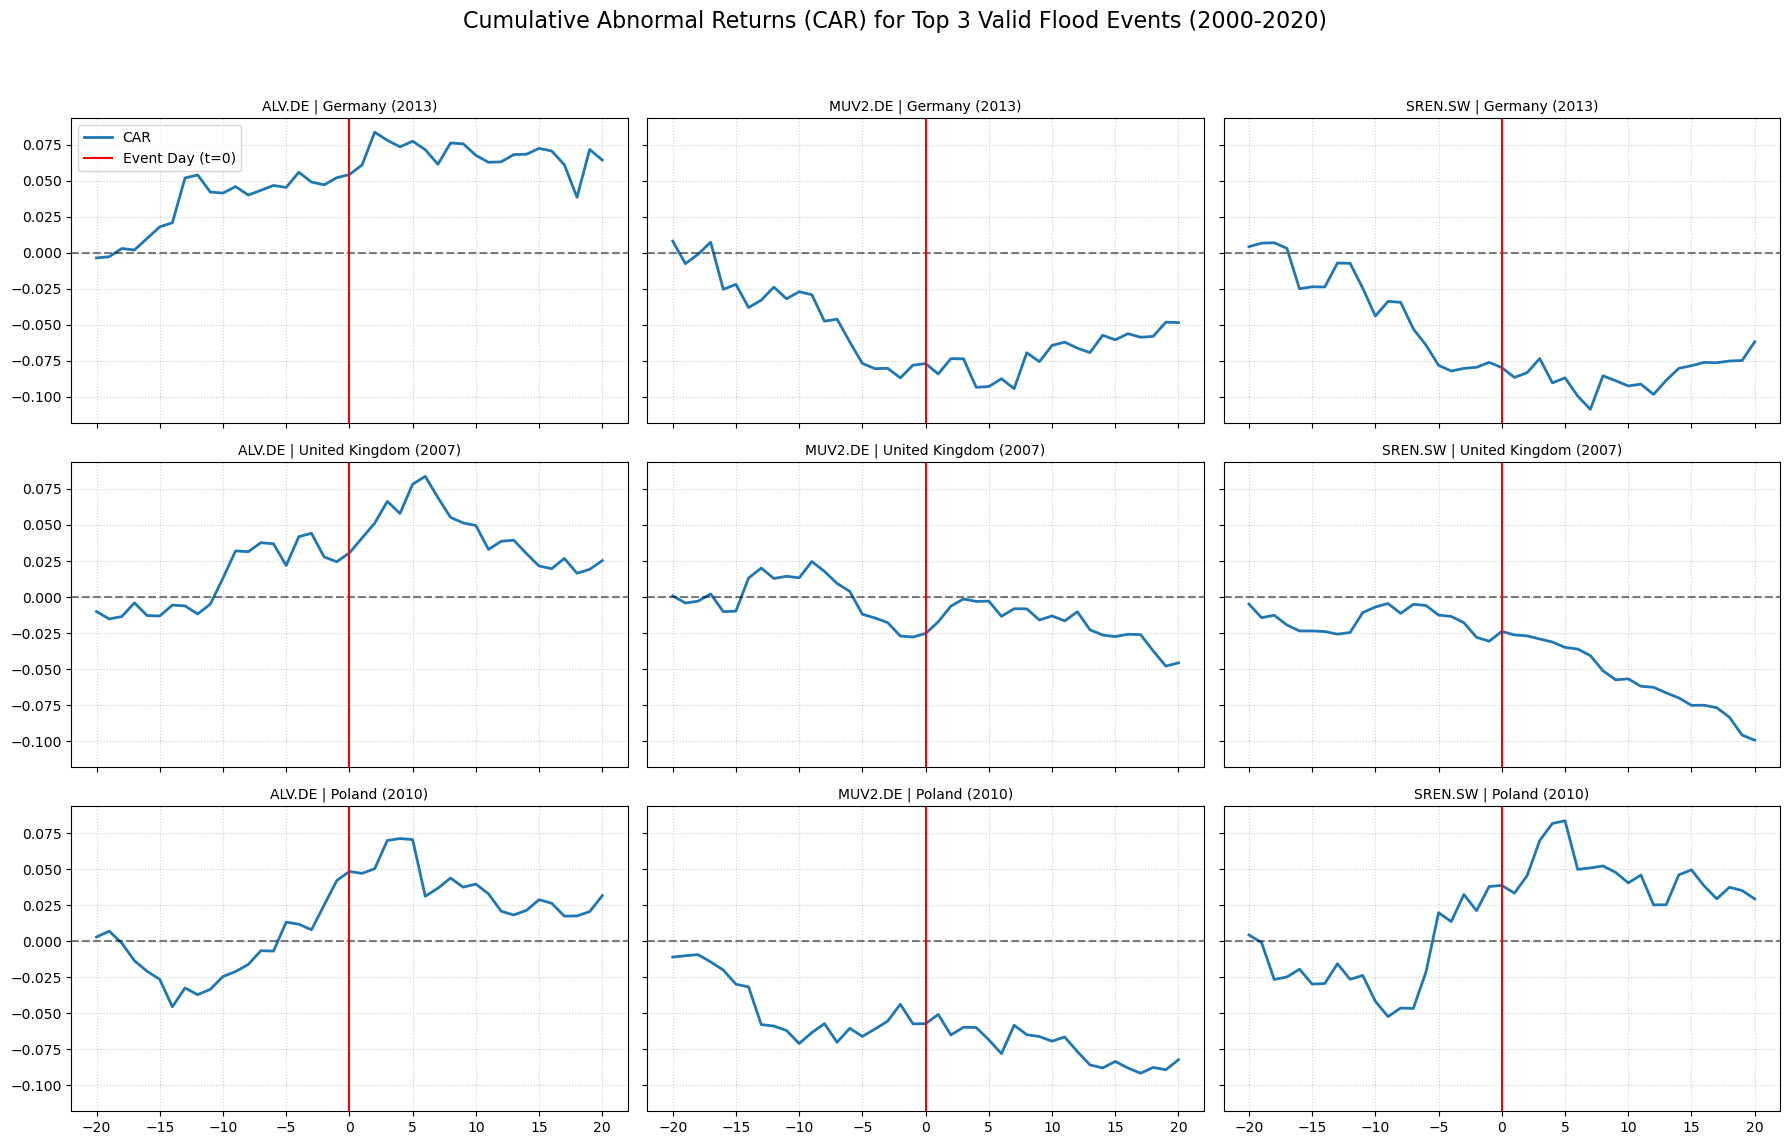

In [26]:
# 5. EXECUTION AND VISUALIZATION PIPELINE

fig, axes = plt.subplots(3, 3, figsize=(18, 12), sharex=True, sharey=True)
fig.suptitle('Cumulative Abnormal Returns (CAR) for Top 3 Valid Flood Events (2000-2020)', fontsize=16)

# Sort all floods in the period by magnitude
all_sorted_floods = df_period.sort_values(by='Losses (2020 euro)', ascending=False)

valid_rows = 0

for index, flood in all_sorted_floods.iterrows():
    if valid_rows >= 3:
        break # Stop automatically once we have 3 successful rows plotted
        
    raw_event_date = flood['Start date']
    flood_location = flood['Country name']
    flood_year = flood['Year']
    
    try:
        trading_date = get_nearest_trading_day(raw_event_date, stock_returns.index)
        
        # Pre-flight check: ensure we have at least 250 days of history before the event
        event_idx = stock_returns.index.get_loc(trading_date)
        if (event_idx - 250) < 0:
            continue # Silently skip this flood and evaluate the next biggest one
            
    except KeyError:
        continue # Skip if the date is completely unmapped
        
    # If the code reaches here, the event has enough data. Let's plot the row!
    for col_idx, ticker in enumerate(tickers):
        ax = axes[valid_rows, col_idx]
        
        # Run the CAPM model and calculate CAR
        capm_model = estimate_capm(stock_returns[ticker], market_returns, trading_date)
        ar, car = calculate_car(capm_model, stock_returns[ticker], market_returns, trading_date)
        
        # Plot the Cumulative Abnormal Returns (CAR)
        ax.plot(range(-20, 21), car, label='CAR', color='#1f77b4', linewidth=2)
        ax.axhline(0, color='black', linestyle='--', alpha=0.5)
        ax.axvline(0, color='red', linestyle='-', label='Event Day (t=0)')
        
        # Format the charts
        ax.set_title(f"{ticker} | {flood_location} ({flood_year})", fontsize=10)
        ax.grid(True, linestyle=':', alpha=0.6)
        
        # Add legend only to the first chart
        if valid_rows == 0 and col_idx == 0:
            ax.legend()
            
    # Increment the counter only after successfully plotting all 3 companies for this flood
    valid_rows += 1 

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()